# 라벨 정책과 경계 검증

실제 V3 원본 인덱스와 집계만 사용합니다. 원본·V1/V2는 읽기 전용입니다. 대시보드는 `dashboard/app.py`로 실행합니다.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.common import TABLES, CFG
from src.detail import get_detail
from src.visuals import detail_figure
assert Path(sys.executable).resolve() == Path(CFG['python']).resolve()
print('실제 실행 Python:', sys.executable)
print('시간: raw / 연구 진단용 / 모델 학습 없음')


실제 실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
시간: raw / 연구 진단용 / 모델 학습 없음


In [2]:
labels = pd.read_parquet(TABLES/'label_status_summary.parquet')
level = 'anchor'
display(labels[labels.Tool.eq('01M01') & labels.H.eq(600) & labels.sample_level.eq(level)])

,Tool,sample_level,policy,fault_type,H,L,positive,negative,NA,excluded,denominator,positive_events,negative_assumption
40,01M01,anchor,conservative,low,600,60,117,646089,16345,19,662570,13,False
41,01M01,anchor,conservative,high,600,60,45,621336,41170,19,662570,5,False
42,01M01,anchor,conservative,leak,600,60,9,281510,381032,19,662570,1,False
43,01M01,anchor,conservative,any,600,60,171,281420,380960,19,662570,19,False
52,01M01,anchor,research,low,600,60,117,646089,16345,19,662570,13,True
53,01M01,anchor,research,high,600,60,45,623640,38866,19,662570,5,True
54,01M01,anchor,research,leak,600,60,9,333329,329213,19,662570,1,True
55,01M01,anchor,research,any,600,60,171,333224,329156,19,662570,19,True
64,01M01,anchor,sensitivity,low,600,60,117,662424,10,19,662570,13,True
65,01M01,anchor,sensitivity,high,600,60,45,662496,10,19,662570,5,True


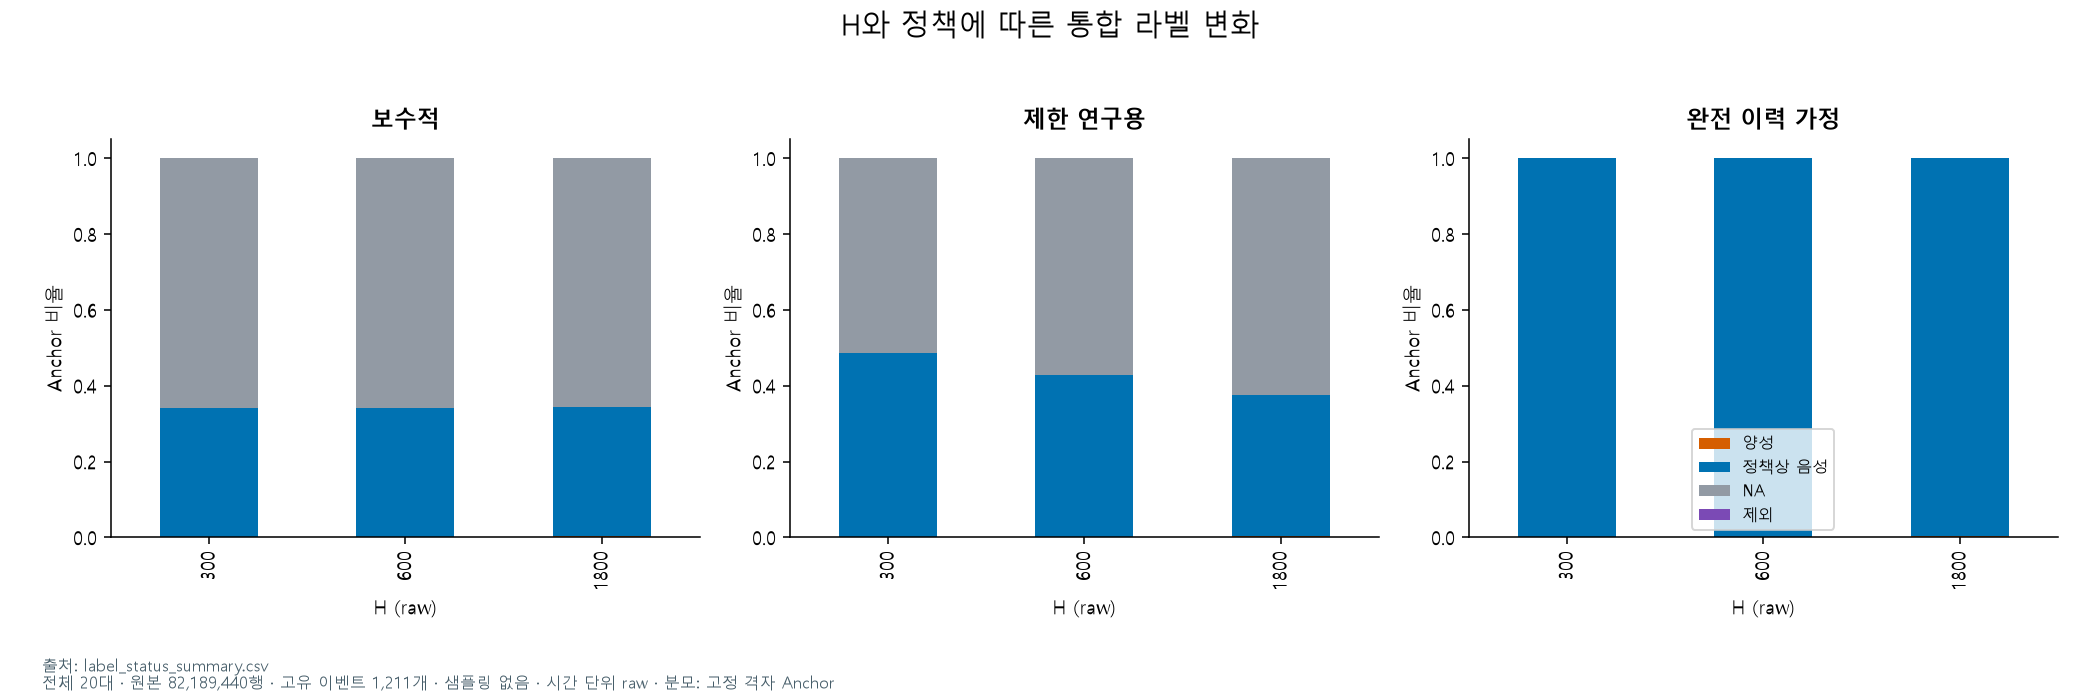

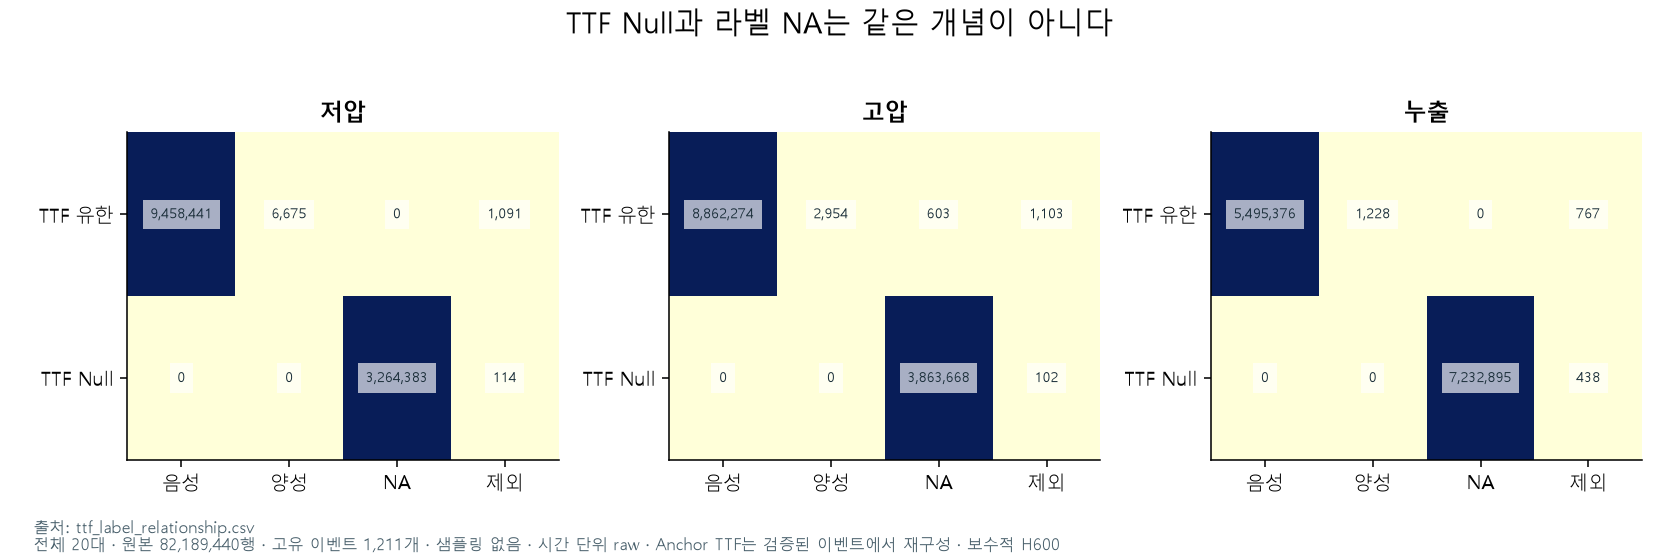

In [3]:
display(Image(filename=str(ROOT/'outputs/figures/label_analysis/horizon_policies.png')))
display(Image(filename=str(ROOT/'outputs/figures/label_analysis/ttf_null_relation.png')))

In [4]:
# 실제 이벤트 주변: 최소 선행시간 경계와 통합 우선순위 확인
events = pd.read_parquet(TABLES/'events.parquet')
event = events[events.Tool.eq('01M01')].iloc[0]
from src.labels import make_labels, STATUS_NAMES
from src.query import manifest
times = [event.fault_time-601,event.fault_time-600,event.fault_time-60,event.fault_time-59,event.fault_time]
result,*_ = make_labels(times,events,'01M01',manifest('01M01')['max_time'])
display(pd.DataFrame({'time':times,**{p:STATUS_NAMES[result[p+'__any__h600']] for p in CFG['policies']}}))

,time,conservative,research,sensitivity
0,6532583.0,NEG,NEG,NEG
1,6532584.0,POS,POS,POS
2,6533124.0,POS,POS,POS
3,6533125.0,EXCLUDE,EXCLUDE,EXCLUDE
4,6533184.0,EXCLUDE,EXCLUDE,EXCLUDE
